# Digit frequencies of π as a growing surface

Each cross-section is the normalized histogram of digit frequencies over the first $n$ digits of π (counting the leading 3).
Stacking cross-sections along $\log_{10} n$ gives a surface; the animation grows it over time.
If π is normal in base 10 (unproved), the surface levels onto the plane $z = 0.1$, with fluctuations of order $0.3/\sqrt{n}$.

In [1]:
import io, sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPImage, display

sys.set_int_max_str_digits(0)
N = 100_000          # number of digits of π

## Digits of π

Machin's formula, $\pi = 16\arctan\tfrac15 - 4\arctan\tfrac1{239}$, in exact integer arithmetic.

In [2]:
def arctan_inv(x, unity):
    s = t = unity // x; x2 = x*x; k = 1; sign = -1
    while t:
        t //= x2; k += 2; s += sign * (t // k); sign = -sign
    return s

unity = 10**(N + 10)
pi = 4*(4*arctan_inv(5, unity) - arctan_inv(239, unity))
digits = np.frombuffer(str(pi)[:N].encode(), dtype=np.uint8) - 48   # 3, 1, 4, 1, 5, ...
assert "".join(map(str, digits[:12])) == "314159265358"
digits[:20]

array([3, 1, 4, 1, 5, 9, 2, 6, 5, 3, 5, 8, 9, 7, 9, 3, 2, 3, 8, 4],
      dtype=uint8)

## Cumulative normalized histograms

Row $n-1$ of `freq` is the histogram of the first $n$ digits. Cross-sections are taken at log-spaced $n$.

In [3]:
onehot = np.zeros((N, 10)); onehot[np.arange(N), digits] = 1
freq = np.cumsum(onehot, 0) / np.arange(1, N+1)[:, None]

ns = np.unique(np.round(np.logspace(0, np.log10(N), 160)).astype(int))
Z = freq[ns-1]
Y = np.log10(ns)
X = np.arange(10)
XX, YY = np.meshgrid(X, Y)

## Rate of leveling

Largest deviation from 0.1 across the ten digits, against the single-digit standard deviation $\sqrt{0.09/n}$.

In [4]:
print(f"{'n':>8} {'max|freq-0.1|':>15} {'0.3/sqrt(n)':>12}")
for n in [10, 100, 1000, 10_000, 100_000]:
    if n <= N:
        print(f"{n:>8,} {np.abs(freq[n-1]-0.1).max():>15.4f} {np.sqrt(0.09/n):>12.4f}")

       n   max|freq-0.1|  0.3/sqrt(n)
      10          0.1000       0.0949
     100          0.0300       0.0300
   1,000          0.0160       0.0095
  10,000          0.0053       0.0030
 100,000          0.0014       0.0009


## Render the animated PNG

In [5]:
def render_frame(k, f, nframes):
    fig = plt.figure(figsize=(8, 6.4), dpi=90)
    ax = fig.add_subplot(projection="3d")
    ax.plot_surface(XX[:k], YY[:k], Z[:k], cmap="viridis", vmin=0, vmax=0.3,
                    rstride=1, cstride=1, linewidth=0.15, edgecolor="k", antialiased=True)
    ax.plot_surface(*np.meshgrid([0, 9], [0, Y[-1]]), np.full((2, 2), 0.1),
                    color="tab:red", alpha=0.12)          # reference plane z = 1/10
    ax.set_xlim(0, 9); ax.set_ylim(0, Y[-1]); ax.set_zlim(0, 1)
    ax.set_xticks(X); ax.set_xlabel("digit")
    ax.set_yticks(range(int(Y[-1]) + 1))
    ax.set_yticklabels([f"$10^{i}$" for i in range(int(Y[-1]) + 1)])
    ax.set_ylabel("n  (log scale)"); ax.set_zlabel("relative frequency")
    ax.view_init(elev=28, azim=-60 + 35 * f / nframes)
    dev = np.abs(Z[k-1] - 0.1).max()
    ax.set_title(f"Digit frequencies in the first n digits of π\n"
                 f"n = {ns[k-1]:,}    max |freq − 0.1| = {dev:.4f}", fontsize=11)
    buf = io.BytesIO(); fig.savefig(buf, format="png"); plt.close(fig)
    return Image.open(buf).convert("RGB")

nframes = 90
frames = [render_frame(max(2, round(len(ns) * f / nframes)), f, nframes)
          for f in range(1, nframes + 1)]

# one shared 256-colour palette for all frames (per-frame palettes get mangled in APNG)
pal = frames[-1].quantize(256)
frames = [fr.quantize(palette=pal, dither=Image.Dither.NONE) for fr in frames]
durations = [60]*(nframes - 1) + [2500]
frames[0].save("pi_digit_surface.png", save_all=True, append_images=frames[1:],
               duration=durations, loop=0, optimize=True)

## Display

Jupyter shows the APNG inline (animation plays in browsers that support APNG, which is all current ones).

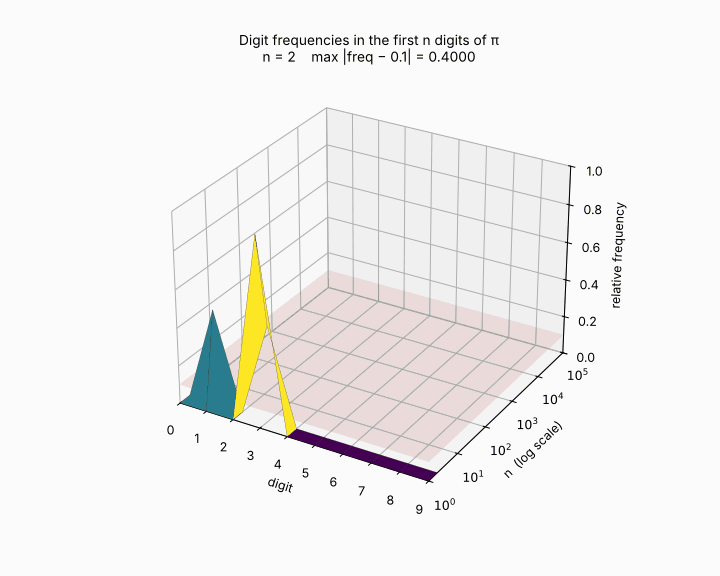

In [6]:
display(IPImage(filename="pi_digit_surface.png"))